# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [2]:
import shutil
import tempfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    gpu = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True) if shutil.which("nvidia-smi") else None
    if gpu is None or gpu.returncode:
        raise RuntimeError("У Colab виберіть GPU T4 перед запуском ноутбука.")
    print(gpu.stdout.strip())
    if shutil.which("ollama") is None:
        if shutil.which("zstd") is None:
            subprocess.run(["sudo", "apt-get", "-qq", "install", "-y", "zstd"], check=True)
        with tempfile.TemporaryDirectory() as directory:
            installer = Path(directory) / "ollama-install.sh"
            subprocess.run(["curl", "-fsSL", "--retry", "3", "-o", str(installer),
                            "https://ollama.com/install.sh"], check=True)
            subprocess.run(["bash", str(installer)], check=True)

Running in Colab: True
GPU 0: Tesla T4 (UUID: GPU-52f6bc9a-615b-11cd-72eb-c500fb3a6d2a)


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [3]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)



try:
    version = ollama("/api/version", timeout=2)
except OSError as error:
    if not IN_COLAB:
        raise RuntimeError("Запустіть Ollama локально на порту 11434.") from error
    with open("/tmp/lab4-ollama.log", "a", encoding="utf-8") as log:
        server = subprocess.Popen(["ollama", "serve"], stdout=log, stderr=subprocess.STDOUT)
    for attempt in range(60):
        try:
            version = ollama("/api/version", timeout=2)
            break
        except OSError:
            if server.poll() is not None:
                raise RuntimeError("Ollama завершила роботу. Перевірте /tmp/lab4-ollama.log.")
            time.sleep(1)
    else:
        raise RuntimeError("Ollama не запустилася. Перевірте /tmp/lab4-ollama.log.")

print("Ollama version:", version["version"])

Ollama version: 0.40.15


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [4]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [5]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [6]:
QUESTION = "Яка столиця Франції?"

In [7]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

#### До питання 7. Промпт для Base у форматі запитання й відповіді

In [8]:
base_prompt = (
    "Запитання: Яка столиця Італії?\nВідповідь: Рим.\n\n"
    "Запитання: Яка столиця Німеччини?\nВідповідь: Берлін.\n\n"
    f"Запитання: {QUESTION}\nВідповідь:"
)
print(base_prompt)
print("Продовження Base:", generate_raw(BASE_MODEL, base_prompt, max_tokens=20))

Запитання: Яка столиця Італії?
Відповідь: Рим.

Запитання: Яка столиця Німеччини?
Відповідь: Берлін.

Запитання: Яка столиця Франції?
Відповідь:
Продовження Base:  Паризька.

Запитання: Яка столиця Польщ


### 1.3. Instruct: модель відповідає на питання

In [9]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [10]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.2 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 5.0 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [11]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 2.0 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.8 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

#### До питання 9. Перевірка задач із відомою відповіддю

In [12]:
import re

reasoning_tasks = [
    ("Ручка й блокнот разом коштують 110 грн. Блокнот на 100 грн дорожчий "
     "за ручку. Скільки гривень коштує ручка?", 5),
    ("Три машини виготовляють три деталі за три хвилини. За скільки хвилин "
     "дев’ять таких машин виготовлять дев’ять деталей?", 3),
    ("Поїзд має 12 вагонів. Оля сидить у четвертому вагоні від початку, "
     "а Ігор — у четвертому від кінця. Скільки вагонів між їхніми вагонами?", 4),
    ("У шухляді 7 чорних, 5 білих і 3 сині шкарпетки. Яку мінімальну кількість "
     "треба витягти навмання, щоб гарантовано мати три шкарпетки одного кольору?", 7),
    ("Число зменшили на 20 відсотків, а потім нове число збільшили на 25 відсотків. "
     "Яке початкове число, якщо в результаті вийшло 80?", 80),
    ("У фермера було 17 овець. Усі, крім 9, втекли. Скільки овець залишилося?", 9),
    ("Скільки цілих чисел від 1 до 200 включно діляться на 3 або на 5, "
     "але не діляться на 7?", 80),
]
found_reasoning_example = False
for task, expected in reasoning_tasks:
    prompt = task + " У фінальній відповіді напиши лише ціле число."
    print(f"\n{prompt}\nОчікувана відповідь: {expected}")
    correct = {}
    for think in (False, True):
        result = chat(INSTRUCT_MODEL, prompt, think=think, max_tokens=3000)
        answer = result["message"]["content"].strip()
        cleaned = answer.strip("*` .\n")
        if not think:
            plain_answer = cleaned
        correct[think] = re.fullmatch(r"[+-]?\d+", cleaned) is not None and int(cleaned) == expected
        print(f"think={think}: {answer!r}, токенів: {result.get('eval_count', 0)}, "
              f"оцінка за форматом: {'правильно' if correct[think] else 'не зараховано'}")
    if correct[True] and not correct[False] and re.fullmatch(r"[+-]?\d+", plain_answer):
        print("Приклад до питання 9: без міркування модель повернула неправильне число.")
        found_reasoning_example = True
        break
if not found_reasoning_example:
    print("На цих запитах потрібного випадку не зафіксовано за заданим критерієм.")

for model_name in (BASE_MODEL, INSTRUCT_MODEL):
    ollama("/api/generate", {"model": model_name, "keep_alive": 0, "stream": False})


Ручка й блокнот разом коштують 110 грн. Блокнот на 100 грн дорожчий за ручку. Скільки гривень коштує ручка? У фінальній відповіді напиши лише ціле число.
Очікувана відповідь: 5
think=False: 'Нехай вартість ручки буде $ x $ гривень. Тоді вартість блокнота — $ x + 100 $ гривень.\n\nЗгідно з умовою, ручка і блокнот разом коштують 110 гривень:\n\n$$\nx + (x + 100) = 110\n$$\n\nРозкриваємо рівняння:\n\n$$\n2x + 100 = 110\n$$\n\nВіднімаємо 100 від обох частин:\n\n$$\n2x = 10\n$$\n\nДіляємо на 2:\n\n$$\nx = 5\n$$\n\nОтже, ручка коштує **5** гривень.\n\nВідповідь: **5**', токенів: 206, оцінка за форматом: не зараховано
think=True: '5', токенів: 280, оцінка за форматом: правильно

Три машини виготовляють три деталі за три хвилини. За скільки хвилин дев’ять таких машин виготовлять дев’ять деталей? У фінальній відповіді напиши лише ціле число.
Очікувана відповідь: 3
think=False: 'Припустимо, що кожна машина виготовляє одну детальну за 3 хвилини. Тоді, якщо маємо 9 машин і 9 деталей, то кожна маш

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [13]:
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "diffusers"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check",
                "transformers==5.20.1", "accelerate==1.15.0",
                "optimum-quanto==0.2.7", "sacrebleu==2.6.0"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '--disable-pip-version-check', 'transformers==5.20.1', 'accelerate==1.15.0', 'optimum-quanto==0.2.7', 'sacrebleu==2.6.0'], returncode=0)

In [14]:
import gc
import time
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sacrebleu.metrics import BLEU, CHRF
from optimum.quanto.library.extensions import get_extension, is_extension_available
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())
print("Compute capability:", torch.cuda.get_device_capability())
print("Апаратний BF16:", torch.cuda.is_bf16_supported(including_emulation=False))


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8 and is_extension_available("quanto_cuda"):
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4
Compute capability: (7, 5)
Апаратний BF16: False


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [15]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
SMALL_MODEL_ID = "Qwen/Qwen3-1.7B"
MODEL_IDS = (MODEL_ID, SMALL_MODEL_ID)
VARIANTS = {"fp16": None, "int8": "int8", "int4": "int4", "int2": "int2"}

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [16]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [17]:
import random
import re


def perplexity(model, tokenizer, text):
    """Експонента середньої похибки передбачення наступного токена."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        return torch.exp(model(ids, labels=ids).loss).item()


def generate(model, tokenizer, prompt, max_new_tokens):
    """Жадібна генерація без режиму міркування."""
    inputs = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True, return_dict=True, return_tensors="pt",
        add_generation_prompt=True, enable_thinking=False,
    ).to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


random_words = re.findall(r"[\w’ʼ'-]+", PPL_TEXT["Українська"])
random.Random(42).shuffle(random_words)
RANDOM_TEXT = " ".join(random_words)
records_by_model = {}
tokenizers = {model_id: AutoTokenizer.from_pretrained(model_id) for model_id in MODEL_IDS}

for model_id in MODEL_IDS:
    tokenizer = tokenizers[model_id]
    model_records = records_by_model[model_id] = {}
    for name, weights in VARIANTS.items():
        print(f"{model_id}, {name}: запуск", flush=True)
        gc.collect()
        torch.cuda.empty_cache()
        config = QuantoConfig(weights=weights) if weights is not None else None
        model = AutoModelForCausalLM.from_pretrained(
            model_id, dtype=DTYPE, device_map={"": DEVICE}, quantization_config=config
        ).eval()
        torch.cuda.reset_peak_memory_stats()
        r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
        for lang, text in PPL_TEXT.items():
            r[f"перплексія, {lang}"] = perplexity(model, tokenizer, text)
        r["переклади"] = [
            generate(model, tokenizer, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION
        ]
        generations = [generate(model, tokenizer, prompt, 200) for prompt in GEN_PROMPTS]
        r["генерації"] = [text for text, _, _ in generations]
        r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
        r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
        if name == "fp16":
            r["параметри"] = sum(parameter.numel() for parameter in model.parameters())
            if model_id == MODEL_ID:
                r["перплексія, перемішані слова"] = perplexity(model, tokenizer, RANDOM_TEXT)
        model_records[name] = r
        del model
        print(f"{model_id}, {name}: готово", flush=True)

torch.cuda.empty_cache()
records = records_by_model[MODEL_ID]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (25 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Qwen/Qwen3-1.7B, int4: готово
Qwen/Qwen3-1.7B, int2: запуск


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Qwen/Qwen3-1.7B, int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [18]:
chrf = CHRF()
bleu = BLEU()
references = [ref for _, ref in TRANSLATION]


def make_summary(model_records):
    return pd.DataFrame.from_dict({
        name: {
            "памʼять моделі, GB": r["памʼять моделі, GB"],
            "пік VRAM, GB": r["пік VRAM, GB"],
            "tokens/s": r["tokens/s"],
            **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
            "chrF перекладу": chrf.corpus_score(r["переклади"], [references]).score,
            "BLEU перекладу": bleu.corpus_score(r["переклади"], [references]).score,
        }
        for name, r in model_records.items()
    }, orient="index")


summaries = {model_id: make_summary(r) for model_id, r in records_by_model.items()}
summary = summaries[MODEL_ID]
display(summary.round(2))

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,15.56,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.69,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.88,2.81,2.76,55.34,29.79
int2,1.81,2.39,2.94,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

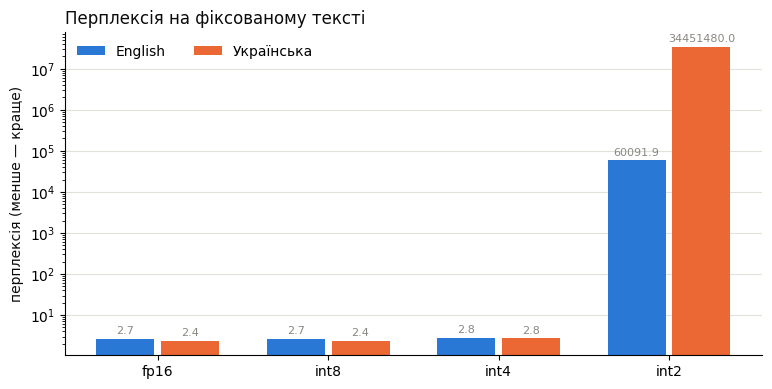

In [19]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [20]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


#### Додаткові вимірювання до питань 1, 5, 12 і 13

In [21]:
word = "трансформер"
letter = "р"
small_tokenizer = tokenizers[SMALL_MODEL_ID]
token_ids = small_tokenizer.encode(word, add_special_tokens=False)
print(f"{word!r}, Qwen3-1.7B: ID {token_ids}, фрагменти {small_tokenizer.convert_ids_to_tokens(token_ids)}")
print(f"Python рахує кириличну {letter!r}: {word.count(letter)}")

fp16 = records["fp16"]
print(f"Параметрів 4B: {fp16['параметри']:,}")
print(f"Оцінка FP16: {fp16['параметри'] * 2 / 1e9:.3f} GB")
print(f"Виміряно FP16: {fp16['памʼять моделі, GB']:.3f} GB")
print("Пік VRAM рахується після завантаження моделі, під час тестових запитів.")
print("Перемішані слова:", RANDOM_TEXT)
print(f"PPL, осмислений текст: {fp16['перплексія, Українська']:.2f}")
print(f"PPL, перемішані слова: {fp16['перплексія, перемішані слова']:.2f}")

sentence_bleu = BLEU(effective_order=True)
sentence_metrics = pd.DataFrame([
    {
        "варіант": name, "джерело": src, "еталон": ref, "переклад": prediction,
        "chrF": chrf.sentence_score(prediction, [ref]).score,
        "BLEU": sentence_bleu.sentence_score(prediction, [ref]).score,
    }
    for name, r in records.items()
    for (src, ref), prediction in zip(TRANSLATION, r["переклади"])
])
display(sentence_metrics.round(2))

'трансформер', Qwen3-1.7B: ID [1792, 34582, 2247, 56619, 7599], фрагменти ['ÑĤ', 'ÑĢÐ°Ð½', 'Ñģ', 'ÑĦÐ¾ÑĢÐ¼', 'ÐµÑĢ']
Python рахує кириличну 'р': 3
Параметрів 4B: 4,022,468,096
Оцінка FP16: 8.045 GB
Виміряно FP16: 8.045 GB
Пік VRAM рахується після завантаження моделі, під час тестових запитів.
Перемішані слова: що який використовує для пігмент які це енергії на рослина відбувається деякі із атмосферу водою і повітря використовує життя які результаті Майже поєднати зелений залежить запас в водорості сонячне дає Землі газ щоб цю харчових з ланцюгів перетворюють поглинає усередині і рослина Він росту в утворюються рослини хлорофіл на вуглекислий процес хімічну світло як листках цукор маленьких якого зелені в із дихаємо та та енергію він переважно Фотосинтез основі глюкоза лежить ґрунту яким структур виділяється від і і називають кисень більшості час У все бактерії кисень ми енергію енергію хлоропластами містять Хлорофіл під світла фотосинтезу
PPL, осмислений текст: 2.40
PPL, перемішані сло

,варіант,джерело,еталон,переклад,chrF,BLEU
0,fp16,The meeting has been moved to Thursday at thre...,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.",49.88,9.98
1,fp16,Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,73.07,52.71
2,fp16,The library is closed on Sundays and public ho...,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,36.70,6.43
3,fp16,"Our team fixed the bug, but the tests are stil...","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...",60.68,24.81
4,fp16,"It is going to rain tomorrow, so take an umbre...","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.",37.12,13.13
5,fp16,"The new model is smaller, but it answers almos...","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...",52.37,16.54
6,fp16,I would like to book a table for two for seven...,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,41.75,8.52
7,fp16,The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,44.43,20.56
8,fp16,Students must submit their lab work before the...,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,60.54,23.36
9,fp16,"If the server does not respond, restart it and...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",83.66,60.77


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [22]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [23]:
while True:
    votes = input("Введіть п’ять оцінок A, B або = через пробіл і натисніть Enter: ").upper().split()
    if len(votes) == len(GEN_PROMPTS) and all(vote in ("A", "B", "=") for vote in votes):
        break
    print("Потрібно рівно п’ять оцінок. Формат: A B = A B")

VOTES = dict(enumerate(votes, start=1))

Введіть п’ять оцінок A, B або = через пробіл і натисніть Enter: B B A B B


In [24]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,int4
2,Explain in three sentences why the sky is blue.,fp16,int4,fp16
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,fp16


fp16 краща: 3, int4 краща: 2, однаково: 0


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [25]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

### 2.7. Повторення експерименту з Qwen3-1.7B (питання 17)

In [26]:
small_summary = summaries[SMALL_MODEL_ID]
display(small_summary.round(2))

ppl_columns = [f"перплексія, {lang}" for lang in PPL_TEXT]
changes = {}
for model_id, metrics in summaries.items():
    relative_ppl = metrics[ppl_columns].div(metrics.loc["fp16", ppl_columns]).sub(1).mul(100)
    relative_ppl.columns = [f"{col}, зміна %" for col in ppl_columns]
    relative_ppl["chrF, зміна в пунктах"] = metrics["chrF перекладу"] - metrics.loc["fp16", "chrF перекладу"]
    changes[model_id] = relative_ppl
display(pd.concat(changes, names=["модель", "варіант"]).round(2))

small_records = records_by_model[SMALL_MODEL_ID]
small_translations = pd.DataFrame({"еталон": references}, index=[src for src, _ in TRANSLATION])
for name, r in small_records.items():
    small_translations[name] = r["переклади"]
display(small_translations)

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"#### Запит {i + 1}: {prompt}"))
    for name, r in small_records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.45,4.02,22.37,4.35,3.10,48.74,23.83
int8,2.04,2.61,13.36,4.45,3.11,47.44,22.54
int4,1.38,1.95,7.21,7.52,5.60,29.01,4.30
int2,1.03,1.60,7.14,438691.38,5951889.50,0.24,0.26


перплексія, English, зміна %  \
модель                      варіант                                 
Qwen/Qwen3-4B-Instruct-2507 fp16                             0.00   
                            int8                            -0.27   
                            int4                             4.99   
                            int2                       2247489.98   
Qwen/Qwen3-1.7B             fp16                             0.00   
                            int8                             2.48   
                            int4                            72.96   
                            int2                      10091678.94   

                                     перплексія, Українська, зміна %  \
модель                      варіант                                    
Qwen/Qwen3-4B-Instruct-2507 fp16                        0.000000e+00   
                            int8                        1.500000e-01   
                            int4                        1.517000e+01   
                            int2                        1.435376e+09   
Qwen/Qwen3-1.7B             fp16                        0.000000e+00   
                            int8                        4.200000e-01   
                            int4                        8.099000e+01   
                            int2                        1.922116e+08   

                                     chrF, зміна в пунктах  
модель                      варіант                         
Qwen/Qwen3-4B-Instruct-2507 fp16                      0.00  
                            int8                      3.02  
                            int4                      0.12  
                            int2                    -55.03  
Qwen/Qwen3-1.7B             fp16                      0.00  
                            int8                     -1.30  
                            int4                    -19.73  
                            int2                    -48.50

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,Сім'я зустрілася на четверті в три ординарні.,Сім'я зустрілася на четверті години четверга.,Відмітка була змінена на четверві в три оцінки.,良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.","Пожалуйста, надішкіть репортаж до кінця дня.","Пожалуйста, надішкіть звіт до кінця дня.",Відмітку з відповіді на роз'в'язанні відповіді...,çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека відкривається відкрито на понеділки...,Бібліотека відкривається відкрито на понеділки...,Більба закінчена на суб’єдні і підписних днях.,çaçaçaçaça Nel лça Nel天上天上天上天上天上天上天上天上天上天上天上天上...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила помилку, але тестування...","Наша команда виправила помилку, але тестування...","Всього наша команда виправила відмін, але тест...",çaçaçaça良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Відомо, що завтра буде дощ, тому підніміть м’я...","Сьогодні пасмурно, тому під'їдіть до пінту.",Відповідь: Відповідь: Відповідь: Відповідь: Ві...,çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça来讲çaçaçaça...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий моделі менший, але відповідає практично ...","Новий моделі менший, але відповідає практично ...","Такий новий модел більше, ніж давній, але відп...",_ar良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати табліт для двох на семнадц...,Я бажаю забронювати табліт для двох на семнадц...,Я хочу забічь таблі для двох для січора ночі.,良良良 л л л良良良良良 -----\n良良良良良良良良良良良良良良良良良良良良良良良良...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає завтрак і безкоштовний Wi-Fi.,Ціна включає завтрак і безкоштовний Wi-Fi.,Вартість включає у себе завтік і безкон'юк'ю т...,ći Kö成长成长成长成长成长成长成长成长/downloads/downloads/down...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні відправити свої роботи з лабо...,Студенти повинні відправити свої роботи з лабо...,Студенти мають відмінувати свої відмінні робот...,çaçaçaçaçaçaçaçaçaçaça磊çaçaçaçaçaçaçaçaçaçaçaç...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапускайте його...","Якби сервер не відповідало, відновіть його і з...",良良良良 л良良良良icziczść آلicz良良良良良良良良良良良良良良良良良良良良良良...


#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Відповідь:

Тема: Прохання про перенесення здачі лабораторної роботи

Викладачеві,

Прошу перенести здачу лабораторної роботи на тиждень, через хворобу. Відповідно до вимоги, здача має бути здійснена до 15 листопада. Якщо ви маєте змогу, будь ласка, здійсніть здачу на 15 листопада.

Дякую за увагу.

Сподіваюсь на вашу допомогу.

**int8:**

Відповідь:

Тема: Прохання про перенесення здачі лабораторної роботи

Викладачу,

Прошу перенести здачу лабораторної роботи на тиждень, через хворобу. Відповідно до вимоги, здача має бути здійснена до 15 листопада. У мене виникає хвороба, що вимагає відмінку в роботі.

Прошу звернути увагу на це і здійснити перенесення здачі.

Дякую за увагу і допомогу.

Сподіваюсь на вашу доп

... (18 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    # Convert the string to lowercase to make the check case-insensitive
    s_lower = s.lower()
    
    # Remove all non-alphanumeric characters and spaces
    s_clean = ''.join(char for char in s_lower if char.isalnum())
    
    # Check if the cleaned string is equal to its reverse
    return s_clean == s_clean[::-1]
```

### Example usage:

```python
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("racecar"))                        # True
print(is_palindrome("hello"))                          # False
print(is_palindrome("RaceCar"))                        # True
```

### Explanation:
- `s.lower()` converts the string to lowercase.
- `''.join(...)` removes all non-alphanumeric characters and spaces.
- `s_clean[::-

**int8:**

Certainly! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    # Convert the string to lowercase to make the check case-insensitive
    s_lower = s.lower()
    
    # Remove all non-alphanumeric characters and spaces
    cleaned = ''.join(char for char in s_lower if char.isalnum())
    
    # Check if the cleaned string is equal to its reverse
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("racecar"))                        # True
print(is_palindrome("hello"))                          # False
print(is_palindrome("RaceCar"))                        # True
```

### Explanation:
- `s.lower()` converts the string to lowercase.
- `''.join(...)` removes all non-alphanumeric characters and spaces.
- `cleaned[::-1]`

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    return s == s[::-1]
```

### Explanation:
- `s == s[::-1]` compares the original string to its reverse.
- `s[::-1]` creates a reversed copy of the string.
- If both are the same, the string is a palindrome.

You can use this function like so:

```python
print(is_palindrome("racecar"))  # True
print(is_palindrome("hello"))    # False
print(is_palindrome("level"))    # True
```

Let me know if you need a version with additional checks or a more detailed explanation!

**int2:**

ći нći н н́ н н л л́́virt́virtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirt lig ligайте ligайте ligайте ligайтеайте ligайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайте้้้้้้้้țțțțțțțțțțțțțțțțțțțțțțțțțțțțțțțțțțțайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайте

## 3. Відповіді на запитання

### 1. У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.

Модель продовжує послідовність токенів, а підрахунок потребує перевірки кожної літери. Слово розбилося на 5 токенів. `"трансформер".count("р")` дає **3**. Instruct відповіла 1, Thinking — 2.

### 2. Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?

Від FP16 до INT2 PPL зросла з 2,67 до 60 091,86 англійською та з 2,40 до 34 451 480 українською. chrF впала з 55,22 до 0,19, BLEU — з 23,71 до 0,12. Найбільша зміна в усіх метриках між INT4 і INT2.

### 3. Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де може просідати якість при квантизації».

На INT4 PPL зросла на 5% англійською та на 15% українською. Це узгоджується зі слайдом про можливе сильніше просідання на менш представлених мовах.

### 4. Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?

У сліпому тесті FP16 виграла 3 рази, INT4 — 2. У перекладі chrF майже однакова (55,22 і 55,34), а BLEU вища в INT4 (29,79 проти 23,71). Сліпий тест оцінював відповіді на інші завдання.

### 5. Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?

FP16 дала «Надішліть мені звіт до кінця дня», а в еталоні додано «Будь ласка». chrF = 73,07, BLEU = 52,71. chrF враховує часткові збіги за символами, а BLEU залежить від збігів слів і довжини відповіді.

### 6. У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?

Пам’ять зменшилася у 1,82× (INT8), 2,95× (INT4) і 4,44× (INT2). Частина ваг лишається у вищій точності, також зберігаються коефіцієнти квантизації. На T4 швидкість впала з 15,56 до 5,69 / 2,88 / 2,94 ток/с.

### 7. Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат.

Base продовжує текст і після одного запитання може продовжити список. Приклади задають шаблон відповіді. У локальному запуску отримав `Paris.`.

```python
prompt = (
    "Question: What is the capital of Italy?\nAnswer: Rome.\n\n"
    "Question: What is the capital of Germany?\nAnswer: Berlin.\n\n"
    "Question: What is the capital of France?\nAnswer:"
)
result = ollama("/api/generate", {
    "model": BASE_MODEL, "prompt": prompt, "raw": True, "stream": False,
    "keep_alive": 0,
    "options": {"temperature": 0, "seed": 1, "num_predict": 12, "stop": ["\n"]},
})
print(result["response"].strip())  # Paris.
```

### 8. Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?

Без міркувань — 252 токени й 2,2 с. З міркуваннями — 569 токенів і 5,0 с. Різниця — **317 токенів і 2,8 с**. Модель засвоїла під час навчання шаблони міркування англійською й може застосувати їх до українського запитання.

### 9. Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.

Промпт: «У фермера було 17 овець. Усі, крім 9, втекли. Скільки овець залишилося? У фінальній відповіді напиши лише ціле число».

- Без міркувань — **8** (`17 − 9`).
- З міркуваннями — **9** (залишилися ті, що не втекли).

### 10. У функціях generate_raw і chat (розділ 1.1) стоять temperature: 0 і seed: 1. Навіщо?

`temperature=0` вибирає токен із найбільшим логітом. `seed=1` фіксує випадкову вибірку, коли вона використовується.

### 11. Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4 і як це з цим повʼязано?

T4 повернула `(7, 5)`. Вона апаратно підтримує FP16, а перевірка апаратної підтримки BF16 повернула `False`.

### 12. Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.

У моделі **4 022 468 096 параметрів**. У FP16 ваги займають $4{,}022\times16/8\approx8{,}045$ GB, стільки ж показав замір. За формулою із запасом 20% бюджет становить ≈9,65 GB.

### 13. Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат.

PPL показує, наскільки добре модель передбачає наступні токени. Токенізація різних мов дає різні одиниці для усереднення. Після перемішування слів PPL FP16 зросла з **2,40 до 14,60**, бо зв’язки між словами зникли.

### 14. Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?

Окрім ваг, VRAM займають KV-кеш, активації та робочі буфери. У FP16 вага моделі становила 8,04 GB, пік — 8,64 GB.

### 15. Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?

FP16 — 3, INT4 — 2, однакових — 0. П’яти запитів замало для стійкого висновку. Для оцінки частки виборів із похибкою близько ±10 відсоткових пунктів за 95% довіри потрібно близько 100 незалежних порівнянь.

### 16. Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?

В INT2 були повтори, випадкова пунктуація й втрата змісту. Наприклад, замість листа модель повторювала `had` та `hton`. У 4B-INT4 відповіді переважно лишалися зв’язними, а 1.7B-INT4 іноді повторювала «Відповідь:» замість перекладу.

### 17. Повторіть секцію 2 з меншою моделлю (наприклад, Qwen/Qwen3-1.7B). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B.

Так, на INT4 модель 1.7B просіла сильніше. Її PPL зросла на 73% англійською і 81% українською, а chrF впала з 48,74 до 29,01. У 4B PPL зросла на 5% і 15%, а chrF змінилася з 55,22 до 55,34.

### 18. Поясніть принцип параметру OLLAMA_NUM_PARALLEL в ollama з демо?

`OLLAMA_NUM_PARALLEL` задає максимум запитів, які одна завантажена модель обробляє одночасно. Решта чекають у черзі. Більше одночасних контекстів потребують більше пам’яті.

### 19. Чому майже всі сучасні моделі зберігаються в bf16?

BF16 займає 2 байти на параметр і має такий самий діапазон експоненти, як FP32. Широкий діапазон зменшує ризик переповнення й занулення під час навчання.

### 20. Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

OpenAI-сумісний формат дає змогу використовувати той самий клієнт із різними рантаймами. У цій роботі клієнт надсилає запити у форматі API OpenAI до локального Ollama, де відповідає Qwen.

## 1. Звіт про локальний застосунок

### 1.1. Характеристики ПК

| Компонент | Значення | Джерело |
|---|---|---|
| CPU | AMD Ryzen 7 9700X, 8 ядер | Windows |
| RAM | 32 GiB | Windows |
| GPU | NVIDIA GeForce RTX 5070 | `nvidia-smi` |
| VRAM | 12 227 MiB | `nvidia-smi` |
| Пропускна здатність VRAM | 672 GB/s | Специфікація RTX 5070 (28 Гбіт/с × 192 ÷ 8) |

### 1.2. Скільки пам’яті потрібно і якої швидкості очікувати

$$
M_{\mathrm{GB}}\approx P\times\frac{Q}{8}\times(1+O)
$$

$P=4$ млрд параметрів  
$Q$ — біт на параметр  
$O=20\%$ — запас на KV-кеш і рантайм.  

Стеля швидкості — $672/(P\times Q/8)$ ток/с.  

| Формат | Пам’ять із запасом, GB | Стеля, ток/с |
|---|---:|---:|
| FP16 | $4\times\frac{16}{8}\times(1+0{,}20)=8\times1{,}20=9{,}6$ | $\frac{672}{4\times(16/8)}=\frac{672}{8}=84$ |
| Q8_0 | $4\times\frac{8}{8}\times(1+0{,}20)=4\times1{,}20=4{,}8$ | $\frac{672}{4\times(8/8)}=\frac{672}{4}=168$ |
| Q4_K_M | $4\times\frac{4}{8}\times(1+0{,}20)=2\times1{,}20=2{,}4$ | $\frac{672}{4\times(4/8)}=\frac{672}{2}=336$ |

За цією оцінкою всі три варіанти вміщуються у VRAM.

### 1.3. Вибір моделі й рантайму

**Qwen3-4B-Instruct-2507, GGUF Q8_0.** Модель вміщується у VRAM і виконує інструкцію з сортування. Режим міркувань для цього не потрібен. Обрано **Ollama** через швидкість і доступність розгортання.

### 1.4. Початковий замір і перевірка якості

Власний бенчмарк у застосунку. Q8, 10 списків покупок на кожен рівень навантаження, JSON-схема, температура 0, до 440 токенів. Трійки в таблиці — **p50 / p95 / p99**.

| Клієнтів | TTFT, с | Ток/с на клієнта | Throughput, ток/с | Помилки |
|---:|---:|---:|---:|---:|
| 1 | 0,048 / 0,056 / 0,060 | 116,8 / 118,7 / 119,2 | 107,0 | 0 |
| 2 | 0,387 / 0,464 / 0,470 | 116,7 / 120,7 / 120,9 | 112,5 | 0 |
| 4 | 1,096 / 1,253 / 1,279 | 116,6 / 117,5 / 117,6 | 113,3 | 0 |

За одного клієнта отримав **116,8 ток/с** проти теоретичних **168 ток/с**. Частина часу йде на обчислення та роботу з KV-кешем. Q8 правильно розклала **66 із 66** позицій.

### 1.5. Оптимізація і повторний замір

Повторив той самий тест із Q4. Трійки в таблиці — **p50 / p95 / p99**.

| Клієнтів | TTFT, с | Ток/с на клієнта | Throughput, ток/с | Помилки |
|---:|---:|---:|---:|---:|
| 1 | 0,047 / 0,060 / 0,067 | 168,1 / 170,9 / 171,1 | 145,1 | 0 |
| 2 | 0,278 / 0,330 / 0,333 | 163,3 / 173,2 / 174,2 | 156,7 | 0 |
| 4 | 0,753 / 0,895 / 0,918 | 170,3 / 174,5 / 174,6 | 158,8 | 0 |

Q4 була швидшою на всіх трьох рівнях і правильно розклала **65 із 66** позицій. Вівсяне молоко потрапило до напоїв замість молочного відділу.

### 1.6. Застосунок «Покупки по відділах»

Вебзастосунок групує покупки за відділами через локальний OpenAI-сумісний API Ollama. Позиції з’являються під час генерації, помилки показуються в інтерфейсі.

Температура **0** для стабільної класифікації. Ліміт **440 токенів** для JSON до 24 позицій. Контекст **4096 токенів** для інструкції, схеми й списку. Запуск описано в `app/README.md`.

### 1.7. Перевірка застосунку

| Сценарій | Очікування | Результат |
|---|---|---|
| 8 покупок | 8 позицій у відділах | 8 позицій |
| Позначення покупки | Лічильник оновлюється | 1 із 8 |
| Десяткові кількості й повтори | Кількості та повтори збережено | Збережено |
| Порожній список | Повідомлення про помилку | Показано |
| Понад 24 позиції або 900 символів | Повідомлення про ліміт | Показано |
| Ollama недоступна або таймаут | Повідомлення про причину | Показано в імітації |
| Пропущена позиція у відповіді | Помилка неповної відповіді | Показано в імітації |
| 24 позиції | 24 коди відділів | 24 коди в обох моделей |

Модель плутала відділи для печериць, зошита й вершкового масла. Уточнив правила для цих товарів у промпті та повторив перевірку.

### 1.8. Висновок

Для застосунку залишив **Q8_0**. Вона правильно розклала всі 66 контрольних позицій. **Q4_K_M** працювала швидше, але помилилася на одній позиції.